# Hotel Harmony: Data Insights for Optimized Operations
**Company:** Elite Hotels International  |  **Dataset:** Hotel Booking Demand (City Hotel + Resort Hotel, 2015-2017)

**Plan**
1. Load the data and take a first look
2. Data cleaning
3. EDA steps from the case study
4. The 25 questions (10 basic, 10 medium, 5 advanced)
5. Final conclusion

**To run in Google Colab:** click the folder icon on the left, upload `hotel_bookings.csv`, then Runtime > Run all.

## 1. Setup and first look

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 50)

# Chart style (you can ignore this part): clean charts, blue first, orange second
BLUE, ORANGE, AQUA, RED = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
LIGHT_BLUE = '#9ec5f4'
plt.rcParams.update({
    'figure.figsize': (9, 4.5),
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#c3c2b7',
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': '#e1e0d9', 'grid.linewidth': 0.8,
    'axes.axisbelow': True,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'text.color': '#0b0b0b', 'lines.linewidth': 2,
    'axes.prop_cycle': cycler(color=[BLUE, ORANGE, AQUA]),
})

In [2]:
# Load the data (the file must be uploaded to Colab first)
df = pd.read_csv('hotel_bookings.csv')
df_raw = df.copy()      # untouched copy, so we can compare before vs after cleaning

print('Rows, columns:', df.shape)
df.head()

Rows, columns: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,01-07-2015
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,01-07-2015
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,02-07-2015
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,02-07-2015
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,03-07-2015


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


**Things that look odd already:**
- `adr` (price per night) has a negative value and a huge value of 5400
- `adults` goes up to 55
- `lead_time` goes up to 737 days
- `children`, `agent`, `company` and `country` have missing values

We fix what is really wrong in the next section.

## 2. Data cleaning

### 2.1 Missing values

In [5]:
missing = df.isnull().sum()
missing = missing[missing > 0]
pd.DataFrame({'missing': missing, 'percent': (missing / len(df) * 100).round(2)})

,missing,percent
children,4,0.00
country,488,0.41
agent,16340,13.69
company,112593,94.31


| Column | What a missing value means | Fix |
|---|---|---|
| `children` (4 rows) | Tiny number, assume no children | fill with 0 |
| `agent` (16,340 rows) | Booked without a travel agent | fill with 0 (0 = no agent) |
| `company` (112,593 rows) | Booked without a company | fill with 0 (0 = no company) |
| `country` (488 rows) | Country not recorded | fill with `'Unknown'` |

In [6]:
df['children'] = df['children'].fillna(0)
df['agent'] = df['agent'].fillna(0)          # 0 = no agent
df['company'] = df['company'].fillna(0)      # 0 = no company
df['country'] = df['country'].fillna('Unknown')

print('Missing values left:', df.isnull().sum().sum())

Missing values left: 0


### 2.2 Date columns

In [7]:
# reservation_status_date is text like '01-07-2015' (day-month-year) -> make it a real date
df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'], format='%d-%m-%Y')

# The arrival date is split into 3 columns (year, month name, day) -> join them into one date
month_to_num = {'January': 1, 'February': 2, 'March': 3, 'April': 4, 'May': 5, 'June': 6,
                'July': 7, 'August': 8, 'September': 9, 'October': 10, 'November': 11, 'December': 12}
df['arrival_month_num'] = df['arrival_date_month'].map(month_to_num)
df['arrival_date'] = pd.to_datetime(dict(year=df['arrival_date_year'],
                                         month=df['arrival_month_num'],
                                         day=df['arrival_date_day_of_month']))

print(df[['arrival_date', 'reservation_status_date']].dtypes)
print('Arrivals from', df['arrival_date'].min().date(), 'to', df['arrival_date'].max().date())

arrival_date               datetime64[ns]
reservation_status_date    datetime64[ns]
dtype: object
Arrivals from 2015-07-01 to 2017-08-31


### 2.3 Duplicate rows

In [8]:
print('Duplicate rows:', df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)
print('Rows after removing duplicates:', len(df))

Duplicate rows: 31994


Rows after removing duplicates: 87396


A duplicate here means every single column is the same. A few could be real separate bookings
(for example, a group booking two identical rooms), but we can't tell them apart, so we drop them.
This is the usual approach for this dataset.

### 2.4 Impossible values

In [9]:
# 1) Bookings with 0 guests (adults + children + babies = 0)
zero_guests = (df['adults'] + df['children'] + df['babies']) == 0
print('Bookings with 0 guests:', zero_guests.sum())

# 2) ADR (price per night) can't be negative, and one value is far above all the others
print('Negative ADR rows:', (df['adr'] < 0).sum())
print('Top 5 ADR values :', df['adr'].nlargest(5).tolist())

# 3) 0-night stays: we keep these, just checking how many there are
print('Bookings with 0 nights (kept):', ((df['stays_in_week_nights'] + df['stays_in_weekend_nights']) == 0).sum())

Bookings with 0 guests: 166
Negative ADR rows: 1
Top 5 ADR values : [5400.0, 510.0, 508.0, 451.5, 450.0]
Bookings with 0 nights (kept): 651


In [10]:
df = df[~zero_guests]                                  # remove 0-guest bookings
df = df[(df['adr'] >= 0) & (df['adr'] < 1000)]         # remove the negative ADR and the 5400 ADR
df = df.reset_index(drop=True)
print('Rows left:', len(df))

Rows left: 87228


ADR = 0 rows are **kept**. They are free or complimentary stays, so they are real bookings.

### 2.5 Fix some columns

In [11]:
# 'Undefined' meal means the same as 'SC' (no meal package)
df['meal'] = df['meal'].replace('Undefined', 'SC')

# These should be whole numbers, not decimals
df[['children', 'agent', 'company']] = df[['children', 'agent', 'company']].astype(int)

df['meal'].value_counts()

meal
BB    67905
SC     9883
HB     9080
FB      360
Name: count, dtype: int64

### 2.6 New columns we will need

In [12]:
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df['revenue'] = df['adr'] * df['total_nights']        # money from one booking = price per night x nights

season_map = {12: 'Winter', 1: 'Winter', 2: 'Winter',
              3: 'Spring', 4: 'Spring', 5: 'Spring',
              6: 'Summer', 7: 'Summer', 8: 'Summer',
              9: 'Autumn', 10: 'Autumn', 11: 'Autumn'}
df['season'] = df['arrival_month_num'].map(season_map)

month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

df[['total_nights', 'total_guests', 'revenue', 'season']].head()

,total_nights,total_guests,revenue,season
0,0,2,0.0,Summer
1,0,2,0.0,Summer
2,1,1,75.0,Summer
3,1,1,75.0,Summer
4,2,2,196.0,Summer


### 2.7 Outliers

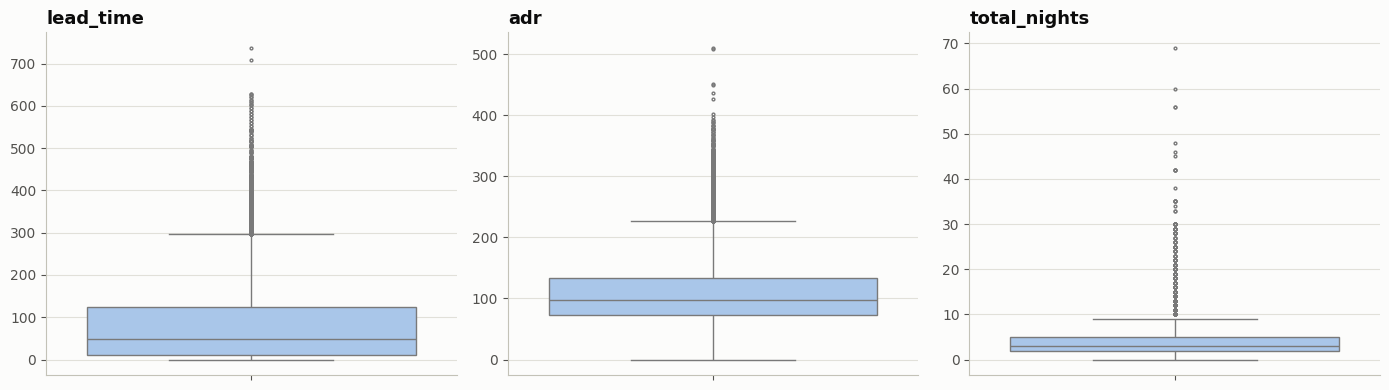

lead_time: 2,394 outliers (2.7% of rows)
adr: 2,507 outliers (2.9% of rows)
total_nights: 2,990 outliers (3.4% of rows)


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ['lead_time', 'adr', 'total_nights']):
    sns.boxplot(y=df[col], ax=ax, color=LIGHT_BLUE, fliersize=2)
    ax.set_title(col)
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

for col in ['lead_time', 'adr', 'total_nights']:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f'{col}: {n:,} outliers ({n / len(df) * 100:.1f}% of rows)')

**Decision: keep them.** Long lead times and long stays are real bookings (think of a big group
booking a year ahead). The only values that looked fake were already removed in 2.4.

### 2.8 Before vs after

In [14]:
print('Before cleaning:', df_raw.shape)
print('After cleaning :', df.shape)
print('Rows removed   :', len(df_raw) - len(df))
print('Missing values :', df.isnull().sum().sum())

Before cleaning: (119390, 32)
After cleaning : (87228, 38)
Rows removed   : 32162
Missing values : 0


## 3. EDA steps (from the case study)

### 3.1 Bookings by hotel type, month and market segment

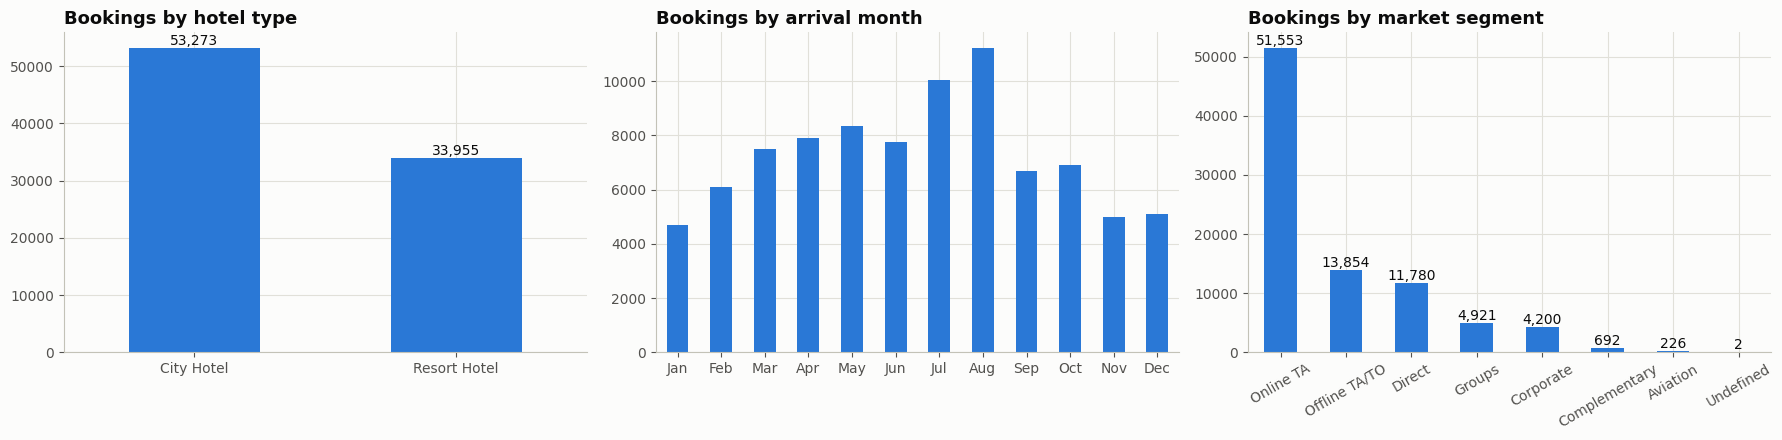

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

hotel_counts = df['hotel'].value_counts()
hotel_counts.plot(kind='bar', ax=axes[0], color=BLUE, rot=0, title='Bookings by hotel type')
axes[0].bar_label(axes[0].containers[0], fmt='{:,.0f}')

month_counts = df['arrival_date_month'].value_counts().reindex(month_order)
month_counts.index = month_counts.index.str[:3]
month_counts.plot(kind='bar', ax=axes[1], color=BLUE, rot=0, title='Bookings by arrival month')

seg_counts = df['market_segment'].value_counts()
seg_counts.plot(kind='bar', ax=axes[2], color=BLUE, rot=30, title='Bookings by market segment')
axes[2].bar_label(axes[2].containers[0], fmt='{:,.0f}')

for ax in axes:
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

**Insight:** City Hotel gets 61% of bookings. Arrivals peak in August and July, with May a clear third. Online TA (travel websites) brings 59% of all bookings, far ahead of Offline TA/TO and Direct.

### 3.2 Lead time vs cancellation

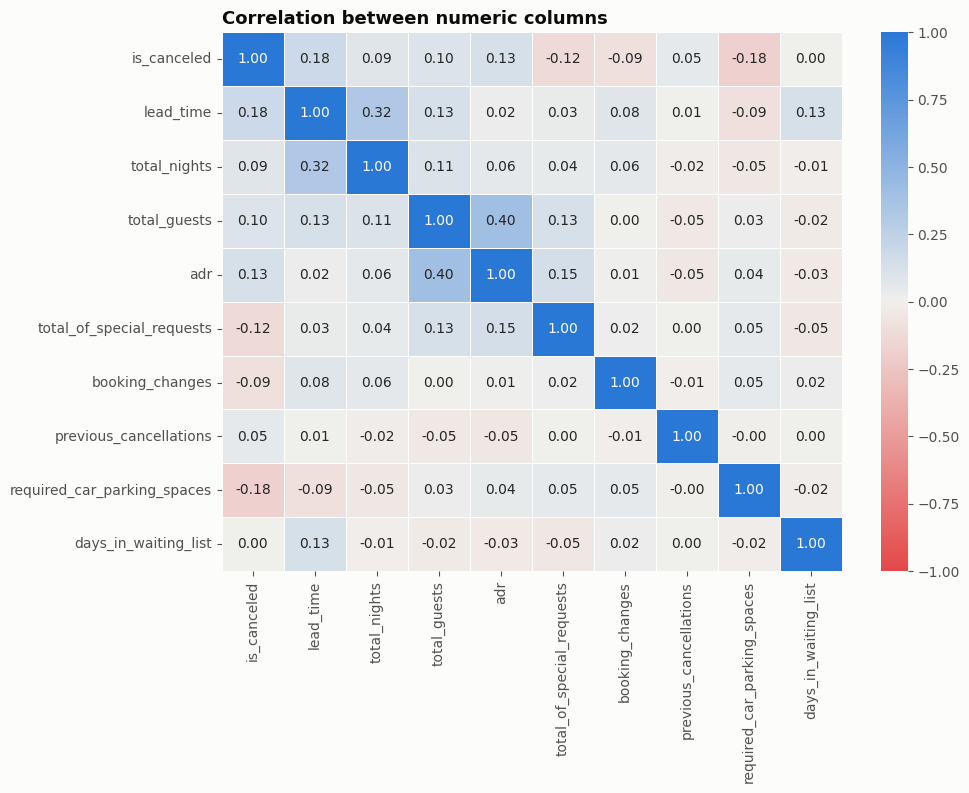

Correlation of lead_time with is_canceled: 0.18


In [16]:
num_cols = ['is_canceled', 'lead_time', 'total_nights', 'total_guests', 'adr',
            'total_of_special_requests', 'booking_changes', 'previous_cancellations',
            'required_car_parking_spaces', 'days_in_waiting_list']
corr = df[num_cols].corr()

blue_red = LinearSegmentedColormap.from_list('blue_red', [RED, '#f0efec', BLUE])   # red = negative, blue = positive
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap=blue_red, vmin=-1, vmax=1, linewidths=0.5)
plt.grid(False)
plt.title('Correlation between numeric columns')
plt.show()

print('Correlation of lead_time with is_canceled:', round(corr.loc['lead_time', 'is_canceled'], 2))

**Insight:** Lead time (0.18) and parking (-0.18) have the strongest links with cancellation, and even those are weak. No single column explains cancellations on its own. Details in Q13 and Q21.

### 3.3 ADR trend over time

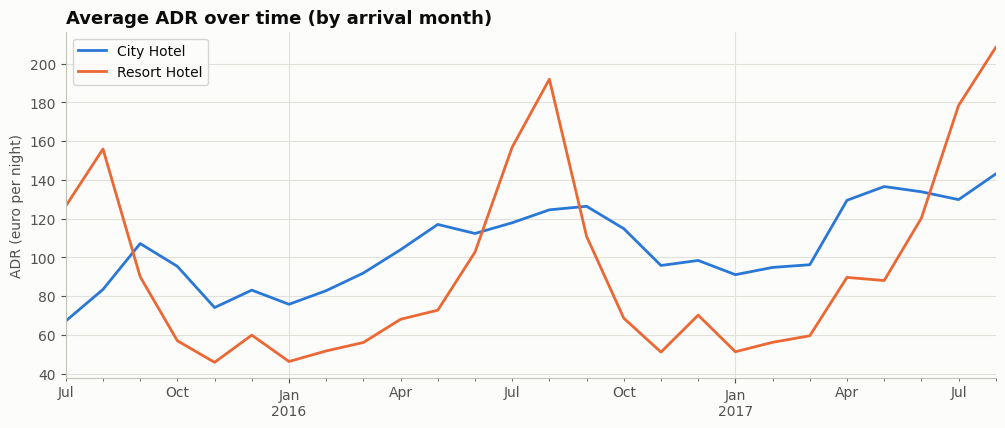

In [17]:
df['year_month'] = df['arrival_date'].dt.to_period('M')
adr_trend = df.groupby(['year_month', 'hotel'])['adr'].mean().unstack()
adr_trend.index = adr_trend.index.to_timestamp()

ax = adr_trend.plot(figsize=(12, 4.5), title='Average ADR over time (by arrival month)')
ax.set_ylabel('ADR (euro per night)')
ax.set_xlabel('')
ax.legend(title='')
plt.show()

**Insight:** The Resort Hotel's price swings with the season: about 49 euro in January but 188 euro in August (average of all years). The City Hotel stays between about 85 and 128 euro all year, so in winter it is the pricier one.

### 3.4 Special requests: how often, and what do they tell us about guest satisfaction?

                           bookings  cancel_rate  repeat_guest_rate  \
total_of_special_requests                                             
0                             43787         33.3                4.1   
1                             28976         22.4                3.4   
2                             11795         21.3                3.2   
3                              2314         17.1                5.0   
4                               320         10.6               16.9   
5                                36          5.6                8.3   

                           share_of_bookings_%  
total_of_special_requests                       
0                                         50.2  
1                                         33.2  
2                                         13.5  
3                                          2.7  
4                                          0.4  
5                                          0.0  


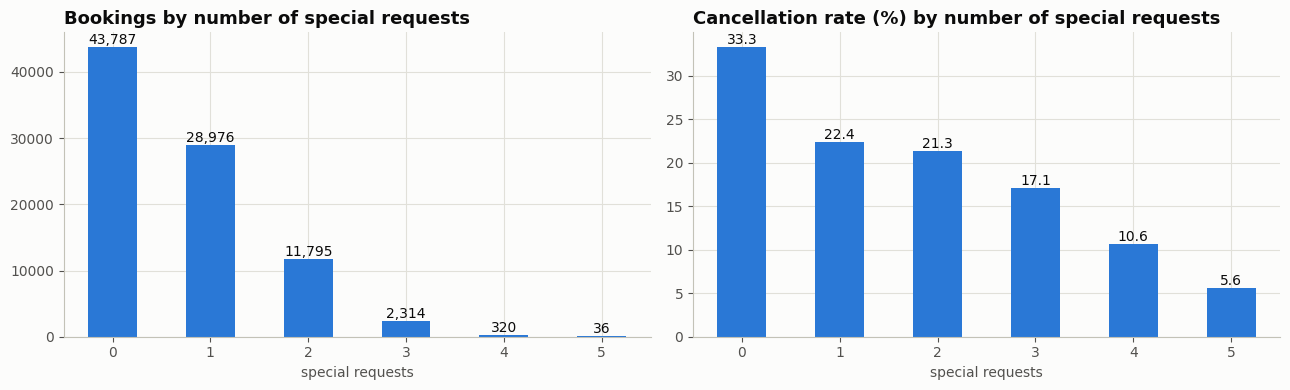

In [18]:
requests = df.groupby('total_of_special_requests').agg(
    bookings=('is_canceled', 'size'),
    cancel_rate=('is_canceled', 'mean'),
    repeat_guest_rate=('is_repeated_guest', 'mean'))
requests['share_of_bookings_%'] = (requests['bookings'] / requests['bookings'].sum() * 100).round(1)
requests['cancel_rate'] = (requests['cancel_rate'] * 100).round(1)
requests['repeat_guest_rate'] = (requests['repeat_guest_rate'] * 100).round(1)
print(requests)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
requests['bookings'].plot(kind='bar', ax=axes[0], color=BLUE, rot=0, title='Bookings by number of special requests')
axes[0].bar_label(axes[0].containers[0], fmt='{:,.0f}')
requests['cancel_rate'].plot(kind='bar', ax=axes[1], color=BLUE, rot=0, title='Cancellation rate (%) by number of special requests')
axes[1].bar_label(axes[1].containers[0], fmt='{:.1f}')
for ax in axes:
    ax.set_xlabel('special requests')
plt.tight_layout()
plt.show()

The data has **no rating or satisfaction column**, so we use two stand-ins: the cancellation rate
and the repeat-guest rate. Guests who stay and come back are more likely to be happy ones.

**Insight:** Half of all bookings have no special request. Cancellations fall steadily as requests go up: 33% with none, 22% with one, and only 6-11% with four or five. Guests who ask for things are more committed to coming.

### 3.5 Key metrics (Metric Development part of the case study)

In [19]:
kpis = pd.DataFrame({
    'Metric': ['Total bookings',
               'Booking lead time (avg days)',
               'Cancellation rate',
               'Avg nights stayed per booking',
               'Special requests per booking',
               'Average ADR (euro per night)',
               'Total revenue from completed stays (euro)'],
    'Value': [f'{len(df):,}',
              f"{df['lead_time'].mean():.1f}",
              f"{df['is_canceled'].mean() * 100:.1f}%",
              f"{df['total_nights'].mean():.2f}",
              f"{df['total_of_special_requests'].mean():.2f}",
              f"{df['adr'].mean():.2f}",
              f"{df.loc[df['is_canceled'] == 0, 'revenue'].sum():,.0f}"]})
kpis.set_index('Metric')

,Value
Metric,
Total bookings,"87,228"
Booking lead time (avg days),80.0
Cancellation rate,27.5%
Avg nights stayed per booking,3.63
Special requests per booking,0.70
Average ADR (euro per night),106.46
Total revenue from completed stays (euro),"22,967,612"


## 4. Questions

### Basic level

### Q1. What is the average lead time for bookings?
*Idea: mean of `lead_time`. Lead time = days between booking and arrival, like booking a Mumbai-Goa train ticket 60 days ahead.*

Average lead time: 80.0 days
Median lead time : 49 days


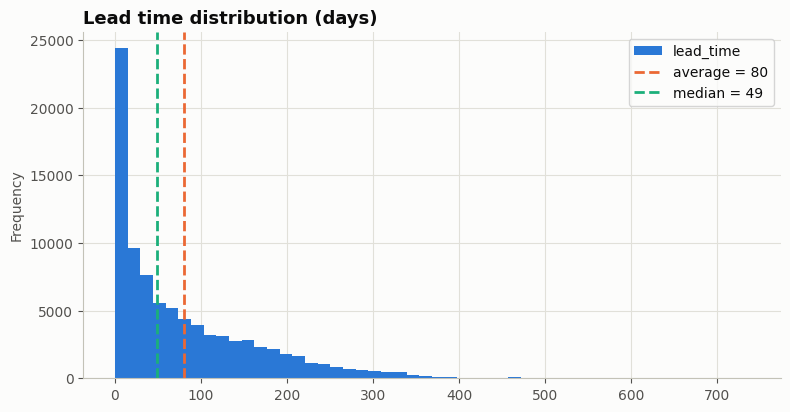

In [20]:
avg_lead = df['lead_time'].mean()
median_lead = df['lead_time'].median()
print(f'Average lead time: {avg_lead:.1f} days')
print(f'Median lead time : {median_lead:.0f} days')

ax = df['lead_time'].plot(kind='hist', bins=50, color=BLUE, title='Lead time distribution (days)')
ax.axvline(avg_lead, color=ORANGE, linestyle='--', label=f'average = {avg_lead:.0f}')
ax.axvline(median_lead, color=AQUA, linestyle='--', label=f'median = {median_lead:.0f}')
ax.legend()
plt.show()

**Insight:** Average is 80 days, but the median is 49, because a few very early bookings pull the average up. A typical guest books about 7 weeks ahead, so campaigns should start around 2 months before a season.

### Q2. What is the distribution of bookings by hotel type?
*Idea: count bookings per hotel and draw a bar chart.*

hotel
City Hotel      53273
Resort Hotel    33955
Name: count, dtype: int64

hotel
City Hotel      61.1
Resort Hotel    38.9
Name: count, dtype: float64


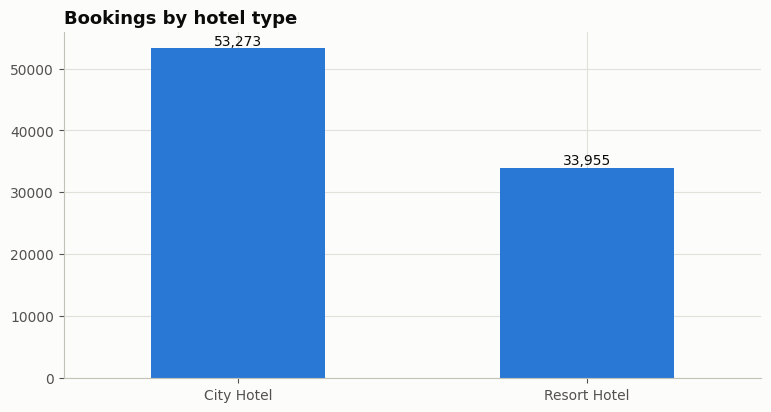

In [21]:
hotel_counts = df['hotel'].value_counts()
print(hotel_counts)
print()
print((hotel_counts / len(df) * 100).round(1))

ax = hotel_counts.plot(kind='bar', color=BLUE, rot=0, title='Bookings by hotel type')
ax.bar_label(ax.containers[0], fmt='{:,.0f}')
ax.set_xlabel('')
plt.show()

**Insight:** City Hotel has 53,273 bookings (61%) and Resort Hotel has 33,955 (39%). City Hotel deserves the bigger share of marketing spend.

### Q3. How many bookings were canceled?
*Idea: sum of `is_canceled` (canceled = 1).*

In [22]:
canceled = df['is_canceled'].sum()
print(f'Canceled bookings: {canceled:,} out of {len(df):,} ({canceled / len(df) * 100:.1f}%)')

Canceled bookings: 24,008 out of 87,228 (27.5%)


**Insight:** 24,008 bookings were canceled, about 1 in 4 (27.5%). Every canceled booking is a room that may sit empty, so this is worth tackling.

### Q4. What is the most common arrival month for bookings?
*Idea: mode of `arrival_date_month`.*

In [23]:
print('Most common arrival month:', df['arrival_date_month'].mode()[0])
print()
print(df['arrival_date_month'].value_counts().head(3))

Most common arrival month: August

arrival_date_month
August    11242
July      10043
May        8344
Name: count, dtype: int64


**Insight:** August is the busiest arrival month (11,242 bookings), then July (10,043) and May (8,344). Plan staff and supplies for July-August first.

### Q5. What is the average number of special requests per booking?
*Idea: mean of `total_of_special_requests`.*

In [24]:
print(f"Average special requests per booking: {df['total_of_special_requests'].mean():.2f}")

Average special requests per booking: 0.70


**Insight:** 0.70 special requests per booking on average, but half of all bookings have none. Most guests ask for little, so the team should be ready for the 1 in 2 who do ask.

### Q6. Which country has the highest number of bookings?
*Idea: count bookings per country (`PRT` = Portugal, `GBR` = United Kingdom, `FRA` = France, `ESP` = Spain, `DEU` = Germany).*

country
PRT    27354
GBR    10423
FRA     8823
ESP     7244
DEU     5385
ITA     3061
IRL     3015
BEL     2081
BRA     1993
NLD     1910
Name: count, dtype: int64


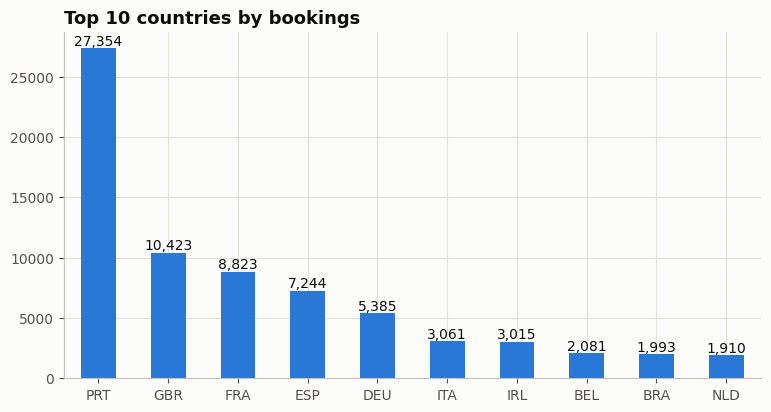

In [25]:
top_countries = df['country'].value_counts().head(10)
print(top_countries)

ax = top_countries.plot(kind='bar', color=BLUE, rot=0, title='Top 10 countries by bookings')
ax.bar_label(ax.containers[0], fmt='{:,.0f}')
ax.set_xlabel('')
plt.show()

**Insight:** Portugal (PRT) is the top country with 27,354 bookings (31%), then the UK, France, Spain and Germany. These top 5 countries make up about 68% of all bookings, so marketing should focus on them.

### Q7. What is the average daily rate (ADR) for each hotel type?
*Idea: group by `hotel` and take the mean of `adr`.*

hotel
City Hotel      111.17
Resort Hotel     99.06
Name: adr, dtype: float64


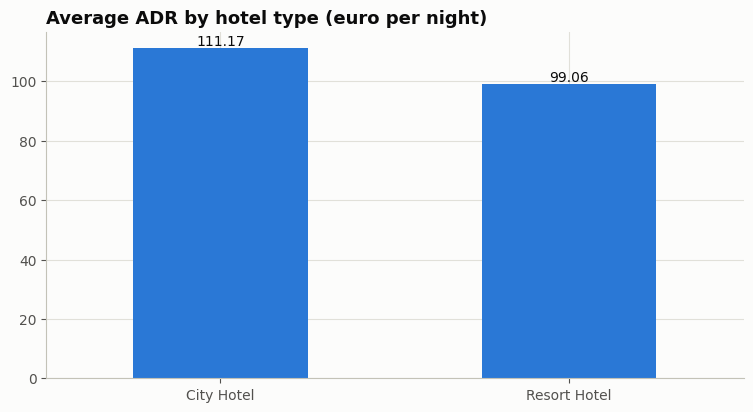

In [26]:
adr_by_hotel = df.groupby('hotel')['adr'].mean().round(2)
print(adr_by_hotel)

ax = adr_by_hotel.plot(kind='bar', color=BLUE, rot=0, title='Average ADR by hotel type (euro per night)')
ax.bar_label(ax.containers[0], fmt='{:.2f}')
ax.set_xlabel('')
plt.show()

**Insight:** City Hotel earns 111.17 euro per night on average, Resort Hotel 99.06 euro. The Resort is cheaper on average, but its summer prices are much higher (see 3.3), so pricing should change by season.

### Q8. What percentage of guests required car parking spaces?
*Idea: share of bookings where `required_car_parking_spaces` is more than 0.*

In [27]:
needs_parking = (df['required_car_parking_spaces'] > 0).sum()
print(f'{needs_parking:,} bookings needed parking = {needs_parking / len(df) * 100:.1f}%')

7,306 bookings needed parking = 8.4%


**Insight:** Only 8.4% of bookings (7,306) needed parking. A small but steady need, and these guests never canceled (see Q21).

### Q9. What is the average stay duration in week nights and weekend nights?
*Idea: mean of `stays_in_week_nights` and `stays_in_weekend_nights`.*

In [28]:
print(f"Average week nights   : {df['stays_in_week_nights'].mean():.2f}")
print(f"Average weekend nights: {df['stays_in_weekend_nights'].mean():.2f}")
print(f"Average total stay    : {df['total_nights'].mean():.2f} nights")

Average week nights   : 2.62
Average weekend nights: 1.00
Average total stay    : 3.63 nights


**Insight:** Guests stay 2.62 week nights and 1.00 weekend night, so 3.63 nights in total. Most stays are short breaks, so pricing deals for 3-4 night packages make sense.

### Q10. How many bookings were made through travel agents?
*Idea: count rows that have an agent. In 2.1 we filled missing agents with 0, so `agent != 0` is the same as the case study's "non-null" hint.*

In [29]:
agent_bookings = (df['agent'] != 0).sum()
print(f'Bookings through travel agents: {agent_bookings:,} ({agent_bookings / len(df) * 100:.1f}%)')
print(f'Bookings without an agent     : {(df["agent"] == 0).sum():,}')

Bookings through travel agents: 75,087 (86.1%)
Bookings without an agent     : 12,141


**Insight:** 75,087 bookings (86%) came through a travel agent. Agents matter a lot, so good relationships with them are important.

### Medium level

### Q11. What is the cancellation rate for each hotel type?
*Idea: group by `hotel`, mean of `is_canceled` x 100.*

hotel
City Hotel      30.1
Resort Hotel    23.5
Name: is_canceled, dtype: float64


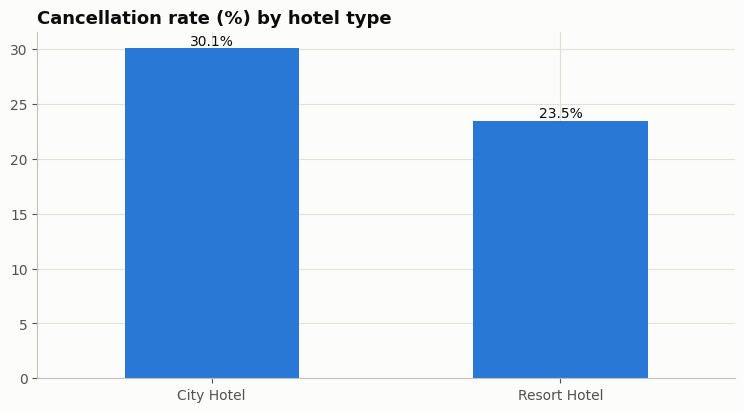

In [30]:
cancel_by_hotel = (df.groupby('hotel')['is_canceled'].mean() * 100).round(1)
print(cancel_by_hotel)

ax = cancel_by_hotel.plot(kind='bar', color=BLUE, rot=0, title='Cancellation rate (%) by hotel type')
ax.bar_label(ax.containers[0], fmt='{:.1f}%')
ax.set_xlabel('')
plt.show()

**Insight:** City Hotel cancels 30.1% of bookings versus 23.5% for Resort Hotel. The City Hotel needs the stricter cancellation policy.

### Q12. What is the average ADR per market segment?
*Idea: group by `market_segment`, mean of `adr`.*

market_segment
Online TA        118.30
Direct           116.78
Aviation         100.61
Offline TA/TO     81.57
Groups            75.18
Corporate         68.34
Undefined         15.00
Complementary      3.09
Name: adr, dtype: float64


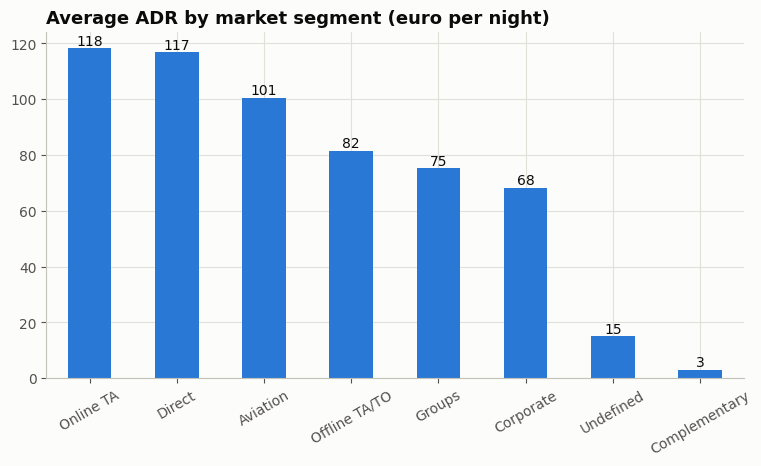

In [31]:
adr_by_segment = df.groupby('market_segment')['adr'].mean().sort_values(ascending=False).round(2)
print(adr_by_segment)

ax = adr_by_segment.plot(kind='bar', color=BLUE, rot=30, title='Average ADR by market segment (euro per night)')
ax.bar_label(ax.containers[0], fmt='{:.0f}')
ax.set_xlabel('')
plt.show()

**Insight:** Online TA (118 euro) and Direct (117 euro) pay the most per night. Groups (75) and Corporate (68) pay less. Complementary is about 3 euro because those stays are free.

### Q13. What is the relationship between lead time and cancellation rate?
*Idea: scatter plot as the hint says, plus a cleaner view: cancellation rate for each lead-time group.*

Correlation (lead_time vs is_canceled): 0.18

lead_time_group
0-7         8.4
8-30       25.4
31-90      32.0
91-180     35.0
181-365    39.7
365+       40.8
Name: is_canceled, dtype: float64


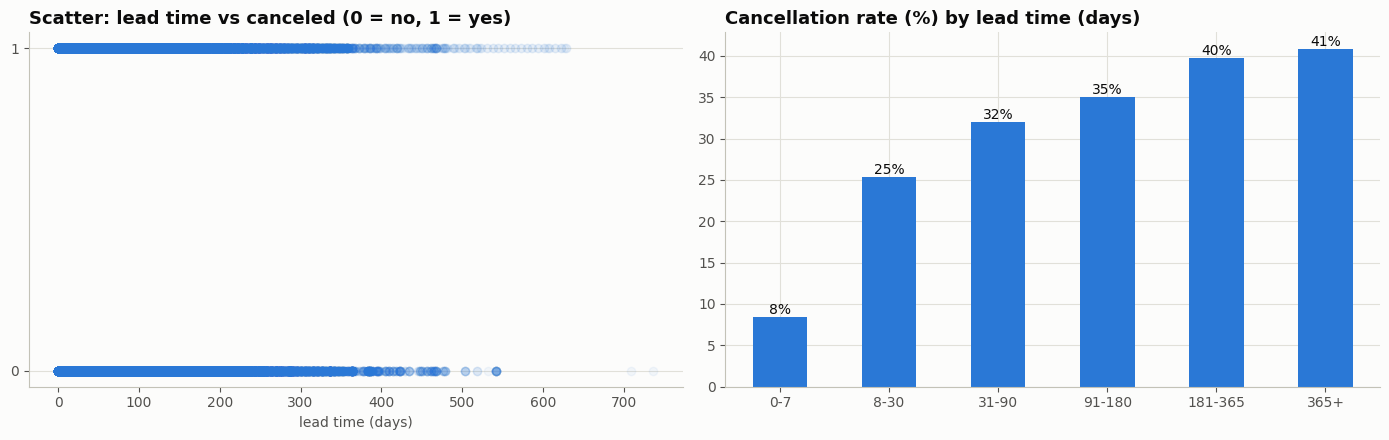

In [32]:
print('Correlation (lead_time vs is_canceled):', round(df['lead_time'].corr(df['is_canceled']), 2))

# Lead-time groups
df['lead_time_group'] = pd.cut(df['lead_time'], bins=[-1, 7, 30, 90, 180, 365, 800],
                               labels=['0-7', '8-30', '31-90', '91-180', '181-365', '365+'])
lead_cancel = (df.groupby('lead_time_group', observed=True)['is_canceled'].mean() * 100).round(1)
print()
print(lead_cancel)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Scatter (hard to read, because is_canceled is only 0 or 1)
axes[0].scatter(df['lead_time'], df['is_canceled'], alpha=0.05, color=BLUE)
axes[0].set_title('Scatter: lead time vs canceled (0 = no, 1 = yes)')
axes[0].set_xlabel('lead time (days)')
axes[0].set_yticks([0, 1])

# Easier to read: cancellation rate per lead-time group
lead_cancel.plot(kind='bar', ax=axes[1], color=BLUE, rot=0, title='Cancellation rate (%) by lead time (days)')
axes[1].bar_label(axes[1].containers[0], fmt='{:.0f}%')
axes[1].set_xlabel('')

plt.tight_layout()
plt.show()

**Insight:** The longer ahead people book, the more they cancel: 8% when booked within a week, around 40% when booked more than 180 days ahead. For long lead-time bookings, ask for a deposit or send a reminder before arrival.

### Q14. Which distribution channel has the highest number of bookings?
*Idea: count bookings per `distribution_channel`.*

distribution_channel
TA/TO        69027
Direct       12953
Corporate     5062
GDS            181
Undefined        5
Name: count, dtype: int64


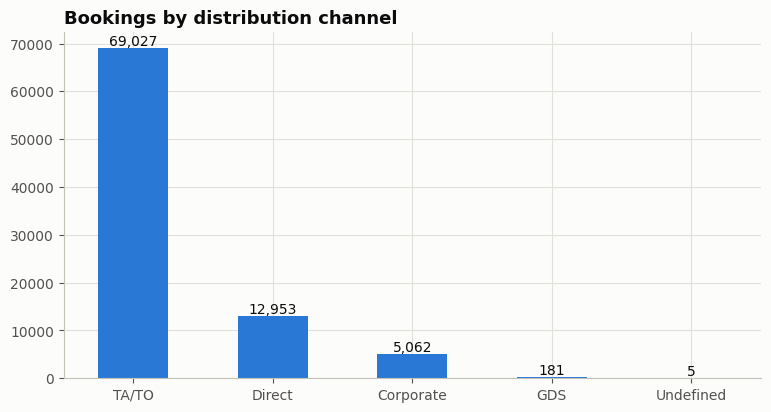

In [33]:
channel_counts = df['distribution_channel'].value_counts()
print(channel_counts)

ax = channel_counts.plot(kind='bar', color=BLUE, rot=0, title='Bookings by distribution channel')
ax.bar_label(ax.containers[0], fmt='{:,.0f}')
ax.set_xlabel('')
plt.show()

**Insight:** TA/TO (travel agents and tour operators) is the biggest channel with 69,027 bookings (79%). Direct is second with 12,953 (15%). Relying this much on one channel is a risk.

### Q15. What is the average number of previous cancellations by hotel type?
*Idea: group by `hotel`, mean of `previous_cancellations`.*

In [34]:
prev_cancel = df.groupby('hotel')['previous_cancellations'].mean().round(3)
print(prev_cancel)

hotel
City Hotel      0.036
Resort Hotel    0.022
Name: previous_cancellations, dtype: float64


**Insight:** Both are very small: City Hotel 0.036 and Resort Hotel 0.022 previous cancellations per booking. Most guests have no cancellation history, so this alone is not a strong warning sign.

### Q16. What is the trend of ADR over the years?
*Idea: average ADR per `arrival_date_year`. Note: 2015 only has Jul-Dec and 2017 only has Jan-Aug, so we also compare just Jul-Aug (the months present in all 3 years).*

All months:
arrival_date_year
2015     92.36
2016    101.57
2017    118.92
Name: adr, dtype: float64

Jul-Aug only:
arrival_date_year
2015    118.93
2016    140.97
2017    157.96
Name: adr, dtype: float64


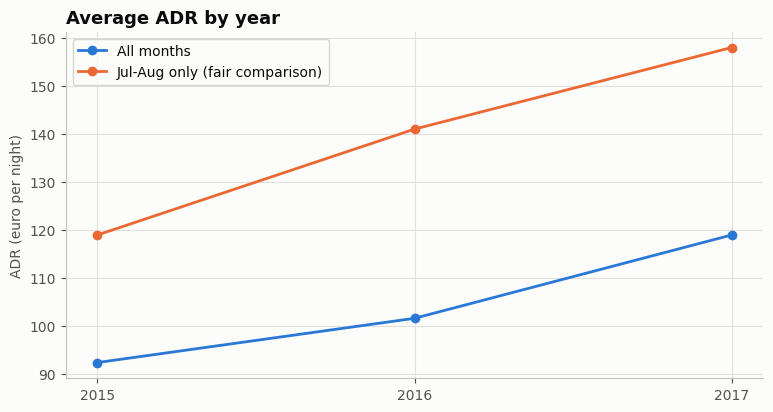

In [35]:
yearly_adr = df.groupby('arrival_date_year')['adr'].mean().round(2)
same_months_adr = df[df['arrival_month_num'].isin([7, 8])].groupby('arrival_date_year')['adr'].mean().round(2)

print('All months:')
print(yearly_adr)
print()
print('Jul-Aug only:')
print(same_months_adr)

ax = yearly_adr.plot(marker='o', label='All months')
same_months_adr.plot(marker='o', ax=ax, label='Jul-Aug only (fair comparison)')
ax.set_xticks([2015, 2016, 2017])
ax.set_xlabel('')
ax.set_ylabel('ADR (euro per night)')
ax.set_title('Average ADR by year')
ax.legend()
plt.show()

**Insight:** ADR rose every year: 92 euro (2015), 102 (2016), 119 (2017). 2015 only covers July-December, so the fair check is July-August only: 119, 141, 158 euro, about 33% higher in two years. Prices are going up, and guests are still booking.

### Q17. Which month has the highest revenue?
*Idea: the case study says to add up ADR per month. That is not real money, so we also calculate revenue = ADR x nights for bookings that were not canceled. Jul and Aug have 3 years of data, the other months only 2, so we also show revenue per year of data.*

                    sum_of_adr  revenue_euro  revenue_per_year_of_data
arrival_date_month                                                    
January               328720.0      705020.0                  352510.0
February              455380.0     1024202.0                  512101.0
March                 607640.0     1415735.0                  707867.0
April                 819232.0     1804557.0                  902278.0
May                   928738.0     2059809.0                 1029905.0
June                  929669.0     2295647.0                 1147824.0
July                 1362972.0     3798500.0                 1266167.0
August               1698164.0     4606618.0                 1535539.0
September             749798.0     1969859.0                  984930.0
October               625118.0     1476095.0                  738047.0
November              362872.0      891886.0                  445943.0
December              417871.0      919684.0                  459842.0

Top m

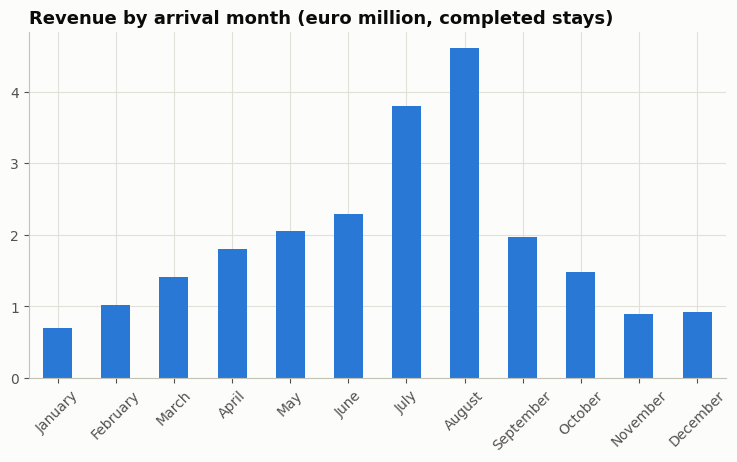

In [36]:
# Method 1: add up ADR per month (the case study hint)
adr_sum = df.groupby('arrival_date_month')['adr'].sum().reindex(month_order)

# Method 2: real revenue = adr x nights, only for bookings that were NOT canceled
real_revenue = df[df['is_canceled'] == 0].groupby('arrival_date_month')['revenue'].sum().reindex(month_order)

# Method 3: same as method 2, but divided by how many years of data each month has
years_per_month = df.groupby('arrival_date_month')['arrival_date_year'].nunique().reindex(month_order)

result = pd.DataFrame({'sum_of_adr': adr_sum,
                       'revenue_euro': real_revenue,
                       'revenue_per_year_of_data': real_revenue / years_per_month}).round(0)
print(result)
print()
print('Top month by sum of ADR      :', result['sum_of_adr'].idxmax())
print('Top month by revenue         :', result['revenue_euro'].idxmax())
print('Top month by revenue per year:', result['revenue_per_year_of_data'].idxmax())

ax = (real_revenue / 1_000_000).plot(kind='bar', color=BLUE, rot=45, title='Revenue by arrival month (euro million, completed stays)')
ax.set_xlabel('')
plt.show()

**Insight:** August earns the most in all three methods: about 4.6 million euro from completed stays, ahead of July at 3.8 million. Even after adjusting for the extra year of Jul-Aug data, August (1.54 million per year) stays on top and January is the lowest (0.35 million).

### Q18. What is the impact of special requests on ADR?
*Idea: correlation between `total_of_special_requests` and `adr`, plus average ADR for each number of requests.*

Correlation: 0.15

total_of_special_requests
0     99.77
1    109.79
2    118.70
3    125.23
4    131.09
5    129.98
Name: adr, dtype: float64


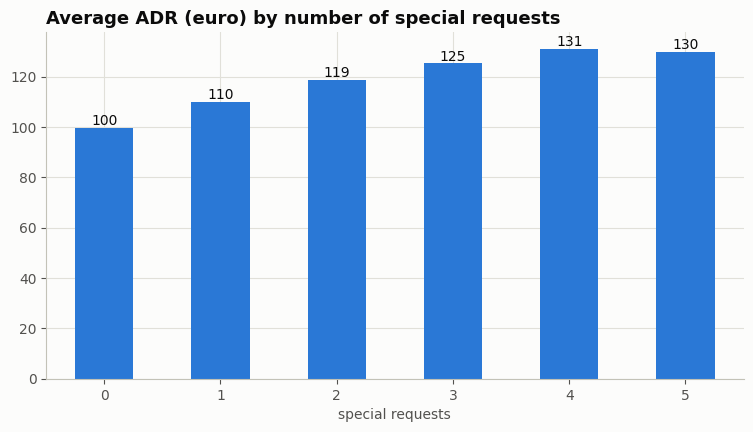

In [37]:
print('Correlation:', round(df['total_of_special_requests'].corr(df['adr']), 2))

adr_by_requests = df.groupby('total_of_special_requests')['adr'].mean().round(2)
print()
print(adr_by_requests)

ax = adr_by_requests.plot(kind='bar', color=BLUE, rot=0, title='Average ADR (euro) by number of special requests')
ax.bar_label(ax.containers[0], fmt='{:.0f}')
ax.set_xlabel('special requests')
plt.show()

**Insight:** A weak positive link (0.15): ADR climbs from about 100 euro with no requests to about 131 euro with four. Guests who pay more tend to ask for more. This does not prove requests cause higher prices.

### Q19. What is the average stay duration for repeated guests versus new guests?
*Idea: group by `is_repeated_guest`, mean of week nights, weekend nights and total nights.*

                stays_in_week_nights  stays_in_weekend_nights  total_nights
New guest                       2.67                     1.03          3.70
Repeated guest                  1.49                     0.46          1.95


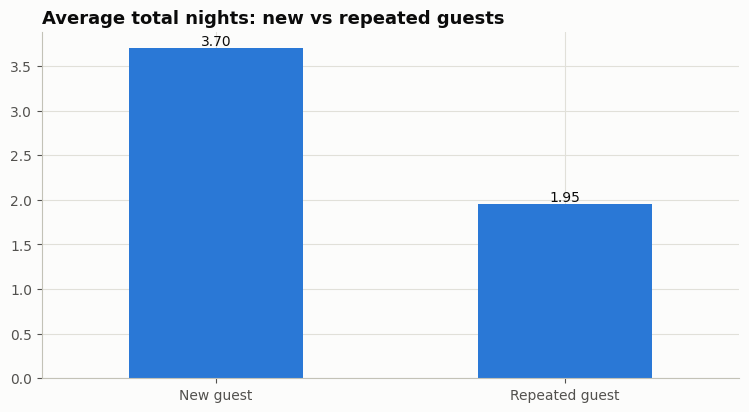

In [38]:
stay = df.groupby('is_repeated_guest')[['stays_in_week_nights', 'stays_in_weekend_nights', 'total_nights']].mean().round(2)
stay.index = ['New guest', 'Repeated guest']
print(stay)

ax = stay['total_nights'].plot(kind='bar', color=BLUE, rot=0, title='Average total nights: new vs repeated guests')
ax.bar_label(ax.containers[0], fmt='{:.2f}')
ax.set_xlabel('')
plt.show()

**Insight:** New guests stay 3.70 nights on average, repeated guests only 1.95, about half as long. Repeat guests come for shorter trips, so loyalty offers should target short stays and weekends.

### Q20. Which room type has the highest number of bookings?
*Idea: count bookings per `reserved_room_type`.*

reserved_room_type
A    56434
D    17376
E     6036
F     2820
G     2050
B      996
C      914
H      596
L        6
Name: count, dtype: int64


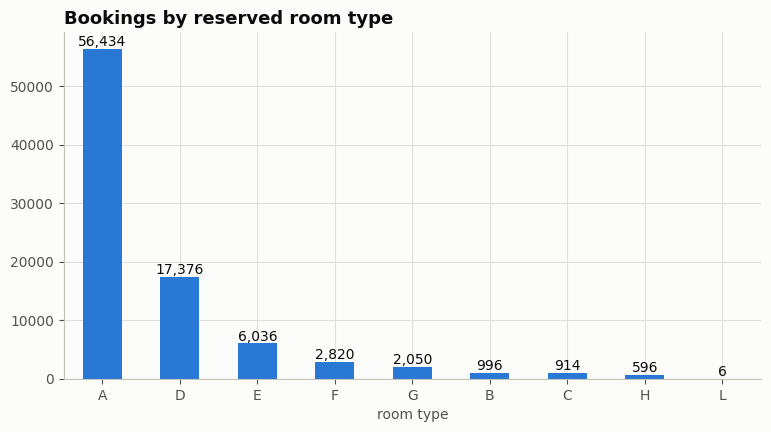

In [39]:
room_counts = df['reserved_room_type'].value_counts()
print(room_counts)

ax = room_counts.plot(kind='bar', color=BLUE, rot=0, title='Bookings by reserved room type')
ax.bar_label(ax.containers[0], fmt='{:,.0f}')
ax.set_xlabel('room type')
plt.show()

**Insight:** Room type A is the most booked by far: 56,434 bookings (65%), then D with 17,376 (20%). Keep most rooms as type A and D.

### Advanced level

### Q21. What factors significantly impact the cancellation rate?
*Idea: logistic regression with `is_canceled` as the target. We do not use `reservation_status`, because it literally says "Canceled" (that would be cheating).*

Cancellation rate - needed parking: 0.0%
Cancellation rate - no parking    : 30.0%



                                coefficient  odds_ratio  p_value significant
deposit_type_Non Refund               3.482      32.533    0.000         Yes
is_repeated_guest                    -0.958       0.384    0.000         Yes
previous_cancellations                0.598       1.818    0.000         Yes
previous_bookings_not_canceled       -0.483       0.617    0.000         Yes
total_of_special_requests            -0.369       0.692    0.000         Yes
hotel_Resort Hotel                   -0.366       0.693    0.000         Yes
lead_time                             0.357       1.428    0.000         Yes
booking_changes                      -0.325       0.722    0.000         Yes
adr                                   0.314       1.369    0.000         Yes
total_nights                          0.126       1.134    0.000         Yes
total_guests                          0.096       1.101    0.000         Yes
days_in_waiting_list                 -0.083       0.920    0.000         Yes

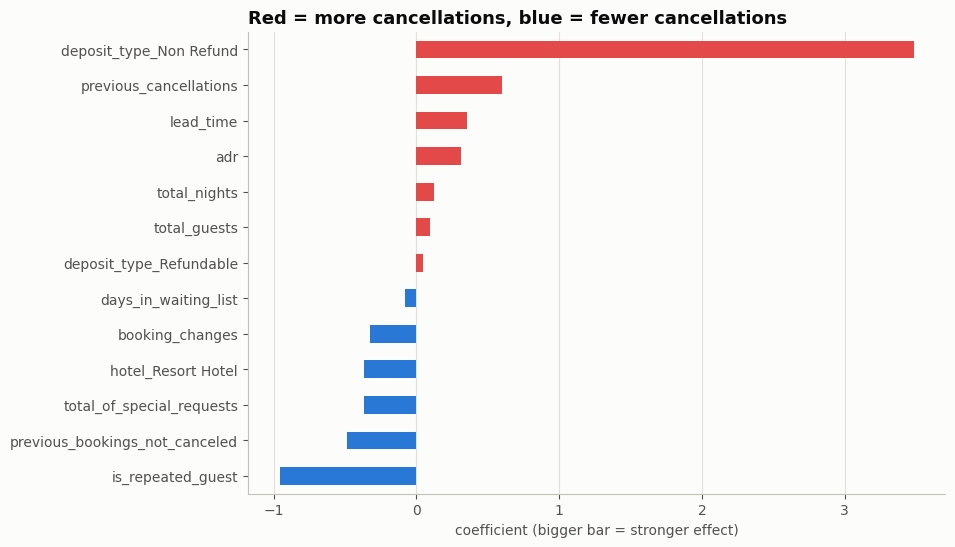

In [40]:
# Every booking that needed a parking space was kept (0% canceled). A perfect 0% breaks logistic
# regression, so parking is left out of the model and checked on its own here.
parking = df['required_car_parking_spaces'] > 0
print(f"Cancellation rate - needed parking: {df.loc[parking, 'is_canceled'].mean() * 100:.1f}%")
print(f"Cancellation rate - no parking    : {df.loc[~parking, 'is_canceled'].mean() * 100:.1f}%")
print()

number_cols = ['lead_time', 'booking_changes', 'total_of_special_requests', 'previous_cancellations',
               'previous_bookings_not_canceled', 'days_in_waiting_list',
               'adr', 'total_nights', 'total_guests']

# Put number columns on the same scale (average 0), so the coefficients can be compared fairly
X = (df[number_cols] - df[number_cols].mean()) / df[number_cols].std()

# Add yes/no columns and text columns turned into 0/1 columns
X = X.join(df[['is_repeated_guest']])
X = X.join(pd.get_dummies(df[['hotel', 'deposit_type']], drop_first=True, dtype=float))
X = sm.add_constant(X)
y = df['is_canceled']

logit_model = sm.Logit(y, X).fit(disp=0)

results = pd.DataFrame({'coefficient': logit_model.params,
                        'odds_ratio': np.exp(logit_model.params),
                        'p_value': logit_model.pvalues}).drop('const')
results['significant'] = np.where(results['p_value'] < 0.05, 'Yes', 'No')
results = results.reindex(results['coefficient'].abs().sort_values(ascending=False).index).round(3)
print(results)

pred = (logit_model.predict(X) > 0.5).astype(int)
print(f'\nModel accuracy: {(pred == y).mean() * 100:.1f}%')
print(f'Baseline (always guess "not canceled"): {(1 - y.mean()) * 100:.1f}%')

coef_plot = results['coefficient'].sort_values()
ax = coef_plot.plot(kind='barh', figsize=(9, 6), color=[RED if v > 0 else BLUE for v in coef_plot],
                    title='Red = more cancellations, blue = fewer cancellations')
ax.xaxis.grid(True)
ax.yaxis.grid(False)
ax.set_xlabel('coefficient (bigger bar = stronger effect)')
plt.show()

**Insight:** The strongest driver is the Non Refund deposit: 95% of those bookings were canceled (1,037 bookings), which looks odd and needs checking. Repeated guests cancel much less. More previous cancellations, longer lead time, higher ADR and longer stays push cancellations up. More special requests, more booking changes and the Resort Hotel push them down. Parking bookings were never canceled. The model gets 75.3% right versus 72.5% for always guessing 'not canceled', so it is good for understanding the drivers, not for predicting single bookings.

### Q22. How does the ADR vary with the number of adults, children, and babies?
*Idea: multiple linear regression: `adr` against `adults`, `children`, `babies`.*

          coefficient  p_value
const          62.118      0.0
adults         20.698      0.0
children       38.648      0.0
babies          6.722      0.0

R-squared: 0.181


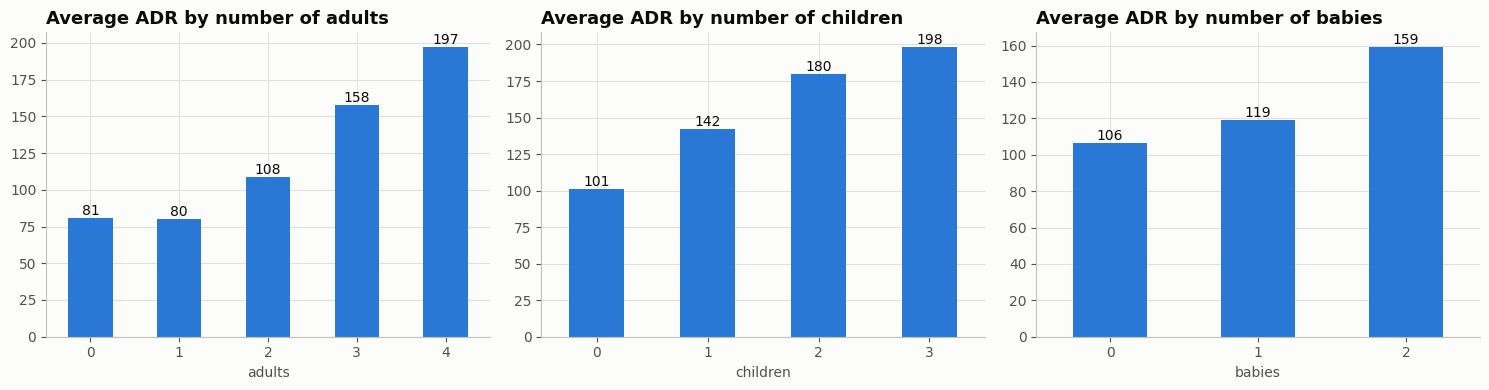

In [41]:
X2 = sm.add_constant(df[['adults', 'children', 'babies']])
ols_model = sm.OLS(df['adr'], X2).fit()

print(pd.DataFrame({'coefficient': ols_model.params, 'p_value': ols_model.pvalues}).round(3))
print('\nR-squared:', round(ols_model.rsquared, 3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, top in zip(axes, ['adults', 'children', 'babies'], [4, 3, 2]):
    avg = df[df[col] <= top].groupby(col)['adr'].mean().round(1)
    avg.plot(kind='bar', ax=ax, color=BLUE, rot=0, title=f'Average ADR by number of {col}')
    ax.bar_label(ax.containers[0], fmt='{:.0f}')
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

**Insight:** Every extra adult adds about 21 euro per night, every child about 39 euro and every baby about 7 euro. All three are significant, and children add the most. R-squared is only 0.18, so guest numbers explain just 18% of the price. Season, hotel and room type matter too.

### Q23. What is the impact of booking changes on guest satisfaction as indicated by special requests?
*Idea: correlation between `booking_changes` and `total_of_special_requests`. There is no satisfaction column, so special requests is our stand-in for how involved the guest is.*

Pearson correlation : 0.018
Spearman correlation: -0.004

0            0.70
1            0.68
2            0.74
3 or more    0.84
Name: total_of_special_requests, dtype: float64


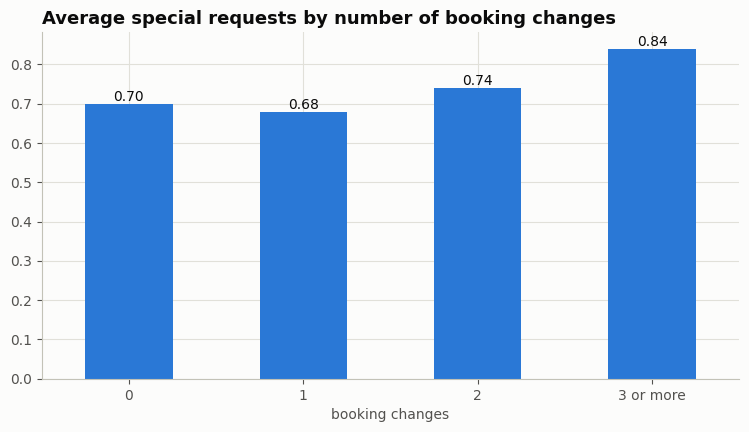

In [42]:
print('Pearson correlation :', round(df['booking_changes'].corr(df['total_of_special_requests']), 3))
print('Spearman correlation:', round(df['booking_changes'].corr(df['total_of_special_requests'], method='spearman'), 3))

changes_group = df['booking_changes'].clip(upper=3)      # 3 means "3 or more"
avg_requests = df.groupby(changes_group)['total_of_special_requests'].mean().round(2)
avg_requests.index = ['0', '1', '2', '3 or more']
print()
print(avg_requests)

ax = avg_requests.plot(kind='bar', color=BLUE, rot=0, title='Average special requests by number of booking changes')
ax.bar_label(ax.containers[0], fmt='{:.2f}')
ax.set_xlabel('booking changes')
plt.show()

**Insight:** Almost no relationship (correlation 0.018). Guests with 3 or more changes ask for a few more things (0.84 vs 0.70), but the gap is small. Booking changes do not tell us much about how guests feel.

### Q24. What is the seasonal impact on booking cancellations?
*Idea: cancellation rate for each month, then grouped into seasons (Winter = Dec-Feb, Spring = Mar-May, Summer = Jun-Aug, Autumn = Sep-Nov).*

arrival_date_month
January      22.1
February     23.2
March        24.4
April        30.5
May          29.3
June         30.3
July         31.8
August       32.2
September    24.6
October      23.7
November     21.2
December     26.9
Name: is_canceled, dtype: float64

season
Winter    24.1
Spring    28.1
Summer    31.6
Autumn    23.3
Name: is_canceled, dtype: float64


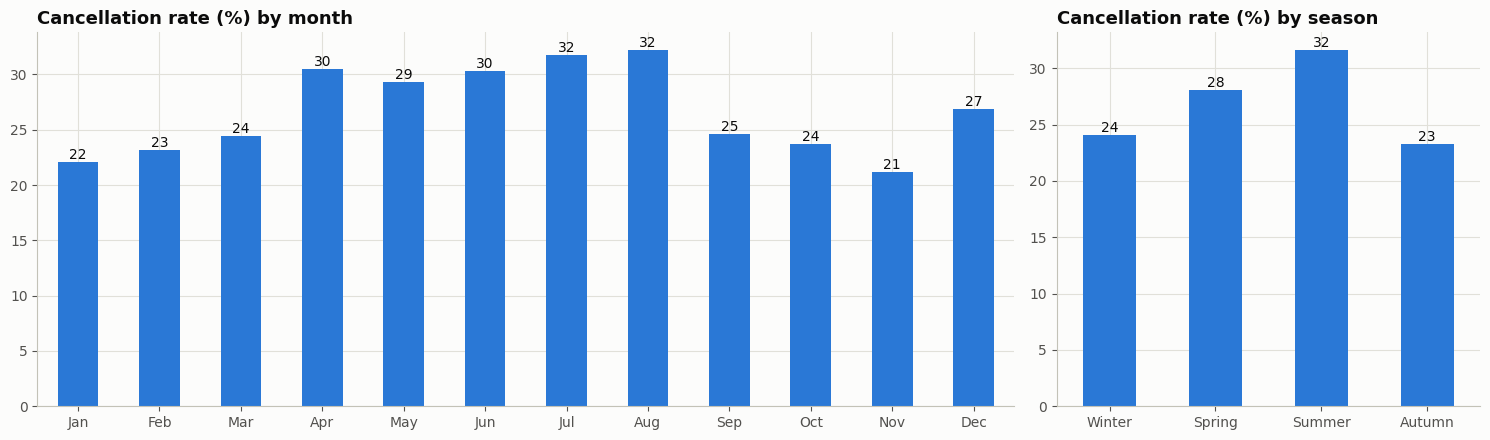

In [43]:
monthly_cancel = (df.groupby('arrival_date_month')['is_canceled'].mean() * 100).reindex(month_order).round(1)
season_cancel = (df.groupby('season')['is_canceled'].mean() * 100).reindex(['Winter', 'Spring', 'Summer', 'Autumn']).round(1)
print(monthly_cancel)
print()
print(season_cancel)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [3, 1.3]})
monthly_cancel.index = monthly_cancel.index.str[:3]
monthly_cancel.plot(kind='bar', ax=axes[0], color=BLUE, rot=0, title='Cancellation rate (%) by month')
axes[0].bar_label(axes[0].containers[0], fmt='{:.0f}')
season_cancel.plot(kind='bar', ax=axes[1], color=BLUE, rot=0, title='Cancellation rate (%) by season')
axes[1].bar_label(axes[1].containers[0], fmt='{:.0f}')
for ax in axes:
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

**Insight:** Cancellations are highest in summer (31.6%), with July and August at about 32% and April and June about 30%. They are lowest in autumn (23.3%) and November (21%). The busiest months also lose the most bookings, so allow a little overbooking in July-August.

### Q25. How does the booking lead time distribution vary between different market segments?
*Idea: box plot of `lead_time` for each `market_segment`.*

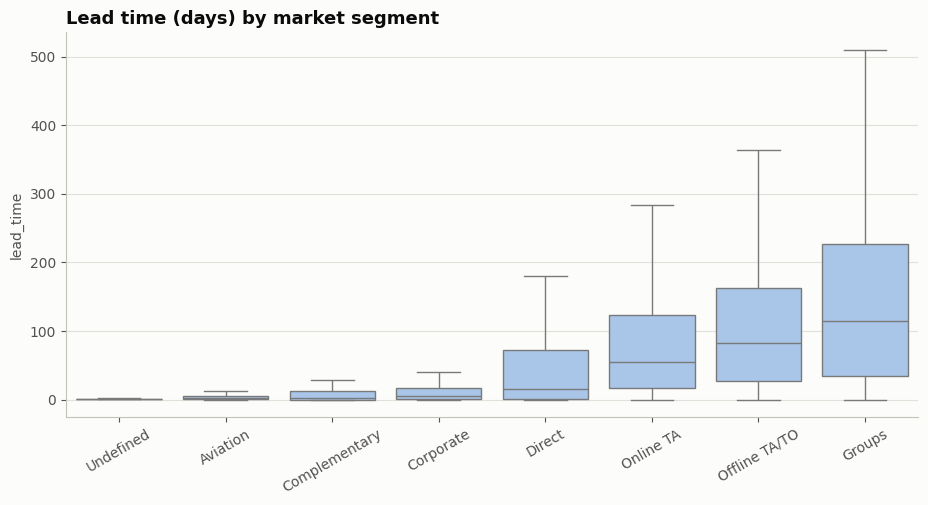

,count,mean,median,max
market_segment,,,,
Undefined,2,1.5,1.5,2
Aviation,226,4.3,3.0,23
Complementary,692,13.8,3.0,386
Corporate,4200,16.3,5.0,343
Direct,11780,48.9,15.0,737
Online TA,51553,80.0,55.0,403
Offline TA/TO,13854,106.2,82.0,532
Groups,4921,147.9,115.0,629


In [44]:
segment_order = df.groupby('market_segment')['lead_time'].median().sort_values().index

plt.figure(figsize=(11, 5))
sns.boxplot(data=df, x='market_segment', y='lead_time', order=segment_order, color=LIGHT_BLUE, showfliers=False)
plt.title('Lead time (days) by market segment')
plt.xlabel('')
plt.xticks(rotation=30)
plt.show()

df.groupby('market_segment')['lead_time'].agg(['count', 'mean', 'median', 'max']).round(1).sort_values('median')

**Insight:** Groups book earliest (median 115 days ahead), then Offline TA/TO (82 days), Online TA (55), Direct (15) and Corporate (5). Aviation and Complementary are about 3 days. Group and agent deals need to be planned months ahead, while Direct and Corporate guests decide late.

## 5. Final conclusion

### Key findings
- After cleaning we have **87,228 bookings**. Most of the 32,162 removed rows were duplicates. **27.5%** of bookings were canceled.
- **City Hotel** gets 61% of bookings, earns more per night (111 vs 99 euro) and cancels more (30.1% vs 23.5%).
- **July and August** are the peak: August is the top month for arrivals and for revenue (about 4.6 million euro from completed stays). Resort Hotel prices jump from about 49 euro in January to 188 euro in August.
- **Online TA** brings 59% of bookings and travel agents and tour operators bring 79% overall. **Portugal** is the top country (31%).
- **Lead time** matters: 8% of bookings made within a week are canceled, about 40% of those made 180+ days ahead.
- **Non Refund deposits** show a 95% cancellation rate, which looks strange.
- **Repeated guests** cancel much less and stay about half as long (1.95 vs 3.70 nights).
- **Special requests** go with fewer cancellations (33% with none, 6-11% with four or five) and higher ADR.
- **ADR is rising**: July-August prices are about 33% higher in 2017 than 2015. Each child adds about 39 euro per night, each adult about 21 euro.

### Recommendations
1. **Cut cancellations:** ask for a deposit or send a reconfirmation message for bookings made 90+ days ahead, and keep a small overbooking buffer for July-August.
2. **Plan for peak season:** schedule staff and supplies around July-August, and run offers in November-February when cancellations and prices are lowest.
3. **Grow Direct bookings:** Direct earns almost the same per night as Online TA (117 vs 118 euro) and Online TA is 59% of all bookings, which is a lot to depend on.
4. **Price by season and guest mix:** keep high summer prices at the Resort Hotel and offer family packages, since children raise ADR the most.
5. **Reward repeat guests** with short-stay and weekend offers, since they book shorter trips and cancel less.
6. **Focus marketing** on the top 5 countries (Portugal, UK, France, Spain, Germany), about 68% of bookings.

### Areas for further investigation
- Why Non Refund bookings cancel 95% of the time: a real pattern or a data problem?
- The data has no guest rating, so satisfaction was only estimated from special requests and cancellations. Collecting review scores would answer this properly.
- Only July-August appear in all three years, so yearly comparisons are limited. More data would give a clearer trend.
- Duplicate rows were removed on the assumption they were repeats. Checking with the booking team would confirm this.
- Compare reserved vs assigned room type to see how often guests get a different room, and whether that affects cancellations.